In [1]:
!pip install pandas numpy matplotlib seaborn google-api-python-client vaderSentiment

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from googleapiclient.discovery import build
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

print("All libraries imported successfully!")

All libraries imported successfully!


In [15]:
from google.colab import userdata
from googleapiclient.discovery import build

API_KEY = userdata.get("YOUTUBE_API_KEY")

if not API_KEY:
    raise ValueError("API key not found!")

youtube = build(
    "youtube",
    "v3",
    developerKey=API_KEY
)

print("YouTube API connected successfully!")

YouTube API connected successfully!


In [16]:
request = youtube.videos().list(
    part="snippet",
    id=video_ids[0]
)

response = request.execute()

print("API is working!")

API is working!


In [17]:


from googleapiclient.errors import HttpError
import pandas as pd

# Add your ORIGINAL YouTube Video IDs here

video_ids = [
    "Xz7lV9e-g-k",
    "829jNYqfjZA",
    "hiY43yua4JE",
    "OSBf8wgZTMI",
    "Q0WVhoLRMu8"
]

# Store all comments
all_comments = []

# Collect maximum 500 comments from each video

for video_id in video_ids:

    page_token = None
    video_count = 0

    print(f"\nCollecting comments from: {video_id}")

    try:

        while video_count < 500:

            request = youtube.commentThreads().list(
                part="snippet",
                videoId=video_id,
                maxResults=100,
                textFormat="plainText",
                pageToken=page_token
            )

            response = request.execute()

            for item in response.get("items", []):

                comment_data = item["snippet"]["topLevelComment"]["snippet"]

                all_comments.append({
                    "video_id": video_id,
                    "comment": comment_data["textDisplay"],
                    "likes": comment_data["likeCount"],
                    "published_at": comment_data["publishedAt"]
                })

                video_count += 1

                if video_count >= 500:
                    break

            page_token = response.get("nextPageToken")

            if not page_token:
                break

        print("Comments collected:", video_count)

    except HttpError as error:
        print(f"Error with video {video_id}: {error}")

# Convert comments into DataFrame

youtube_df = pd.DataFrame(all_comments)

print("\n================================")
print("TOTAL COMMENTS COLLECTED:", len(youtube_df))
print("================================")

display(youtube_df.head(10))



Comments collected: 7

Comments collected: 34

Comments collected: 500

Comments collected: 390

Comments collected: 57

TOTAL COMMENTS COLLECTED: 988


,video_id,comment,likes,published_at
0,Xz7lV9e-g-k,Thank you! I love how u did one side off th...,1,2026-02-08T00:16:46Z
1,Xz7lV9e-g-k,What blush/ bronzer did you use,0,2026-02-07T09:45:51Z
2,Xz7lV9e-g-k,what primer works best with this foundation?,0,2025-12-31T01:34:35Z
3,Xz7lV9e-g-k,Got this foundation today. I have a very oily ...,3,2025-07-19T18:48:23Z
4,Xz7lV9e-g-k,"To help the mess with your bottle, you can use...",2,2024-10-19T12:46:31Z
5,Xz7lV9e-g-k,You’re so pretty,3,2023-12-18T04:41:49Z
6,Xz7lV9e-g-k,I always go back to this foundation,7,2023-12-18T04:36:05Z
7,829jNYqfjZA,Nice brows what’s your favourite eyebrow penci...,0,2023-03-22T06:13:40Z
8,829jNYqfjZA,What’s your foundation shades in Mac and Estée...,0,2023-03-22T06:12:56Z
9,829jNYqfjZA,What shade did you use,0,2023-03-22T06:12:18Z


In [18]:
youtube_df.to_csv(
    "maybelline_youtube_comments.csv",
    index=False
)

print("Comments saved successfully!")

Comments saved successfully!


In [19]:
print("Total comments:", len(youtube_df))

print("\nFirst 10 comments:")
print(youtube_df.head(10))

print("\nDataset information:")
print(youtube_df.info())

Total comments: 988

First 10 comments:
      video_id                                            comment  likes  \
0  Xz7lV9e-g-k  Thank you!  I love  how u did  one side off th...      1   
1  Xz7lV9e-g-k                    What blush/ bronzer did you use      0   
2  Xz7lV9e-g-k       what primer works best with this foundation?      0   
3  Xz7lV9e-g-k  Got this foundation today. I have a very oily ...      3   
4  Xz7lV9e-g-k  To help the mess with your bottle, you can use...      2   
5  Xz7lV9e-g-k                                   You’re so pretty      3   
6  Xz7lV9e-g-k                I always go back to this foundation      7   
7  829jNYqfjZA  Nice brows what’s your favourite eyebrow penci...      0   
8  829jNYqfjZA  What’s your foundation shades in Mac and Estée...      0   
9  829jNYqfjZA                             What shade did you use      0   

           published_at  
0  2026-02-08T00:16:46Z  
1  2026-02-07T09:45:51Z  
2  2025-12-31T01:34:35Z  
3  2025-07-19T18:48

In [20]:
print("Before cleaning:", len(youtube_df))

youtube_df = youtube_df.dropna(subset=["comment"])

youtube_df = youtube_df.drop_duplicates(
    subset=["comment", "video_id"]
)

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"http\S+|www\S+", "", text)

    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()

youtube_df["clean_comment"] = youtube_df["comment"].apply(clean_text)

youtube_df = youtube_df[
    youtube_df["clean_comment"] != ""
]

print("After cleaning:", len(youtube_df))

Before cleaning: 988
After cleaning: 984


In [21]:
youtube_df[["comment", "clean_comment"]].head(10)

,comment,clean_comment
0,Thank you! I love how u did one side off th...,thank you i love how u did one side off the fa...
1,What blush/ bronzer did you use,what blush bronzer did you use
2,what primer works best with this foundation?,what primer works best with this foundation
3,Got this foundation today. I have a very oily ...,got this foundation today i have a very oily s...
4,"To help the mess with your bottle, you can use...",to help the mess with your bottle you can use ...
5,You’re so pretty,you re so pretty
6,I always go back to this foundation,i always go back to this foundation
7,Nice brows what’s your favourite eyebrow penci...,nice brows what s your favourite eyebrow penci...
8,What’s your foundation shades in Mac and Estée...,what s your foundation shades in mac and est e...
9,What shade did you use,what shade did you use


In [22]:
analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):

    score = analyzer.polarity_scores(text)

    compound = score["compound"]

    if compound >= 0.05:
        return "Positive"

    elif compound <= -0.05:
        return "Negative"

    else:
        return "Neutral"

youtube_df["sentiment"] = youtube_df["clean_comment"].apply(
    get_sentiment
)

youtube_df.head(10)

,video_id,comment,likes,published_at,clean_comment,sentiment
0,Xz7lV9e-g-k,Thank you! I love how u did one side off th...,1,2026-02-08T00:16:46Z,thank you i love how u did one side off the fa...,Positive
1,Xz7lV9e-g-k,What blush/ bronzer did you use,0,2026-02-07T09:45:51Z,what blush bronzer did you use,Neutral
2,Xz7lV9e-g-k,what primer works best with this foundation?,0,2025-12-31T01:34:35Z,what primer works best with this foundation,Positive
3,Xz7lV9e-g-k,Got this foundation today. I have a very oily ...,3,2025-07-19T18:48:23Z,got this foundation today i have a very oily s...,Positive
4,Xz7lV9e-g-k,"To help the mess with your bottle, you can use...",2,2024-10-19T12:46:31Z,to help the mess with your bottle you can use ...,Positive
5,Xz7lV9e-g-k,You’re so pretty,3,2023-12-18T04:41:49Z,you re so pretty,Positive
6,Xz7lV9e-g-k,I always go back to this foundation,7,2023-12-18T04:36:05Z,i always go back to this foundation,Neutral
7,829jNYqfjZA,Nice brows what’s your favourite eyebrow penci...,0,2023-03-22T06:13:40Z,nice brows what s your favourite eyebrow penci...,Positive
8,829jNYqfjZA,What’s your foundation shades in Mac and Estée...,0,2023-03-22T06:12:56Z,what s your foundation shades in mac and est e...,Neutral
9,829jNYqfjZA,What shade did you use,0,2023-03-22T06:12:18Z,what shade did you use,Neutral


In [23]:
positive_reviews = youtube_df[
    youtube_df["sentiment"] == "Positive"
]

print("Total Positive Comments:", len(positive_reviews))

positive_reviews.head()

Total Positive Comments: 684


,video_id,comment,likes,published_at,clean_comment,sentiment
0,Xz7lV9e-g-k,Thank you! I love how u did one side off th...,1,2026-02-08T00:16:46Z,thank you i love how u did one side off the fa...,Positive
2,Xz7lV9e-g-k,what primer works best with this foundation?,0,2025-12-31T01:34:35Z,what primer works best with this foundation,Positive
3,Xz7lV9e-g-k,Got this foundation today. I have a very oily ...,3,2025-07-19T18:48:23Z,got this foundation today i have a very oily s...,Positive
4,Xz7lV9e-g-k,"To help the mess with your bottle, you can use...",2,2024-10-19T12:46:31Z,to help the mess with your bottle you can use ...,Positive
5,Xz7lV9e-g-k,You’re so pretty,3,2023-12-18T04:41:49Z,you re so pretty,Positive


In [24]:
negative_reviews = youtube_df[
    youtube_df["sentiment"] == "Negative"
]

print("Total Negative Comments:", len(negative_reviews))

negative_reviews.head()

Total Negative Comments: 87


,video_id,comment,likes,published_at,clean_comment,sentiment
27,829jNYqfjZA,Sorry sis you pakai shade apa ya?,2,2021-03-03T03:59:07Z,sorry sis you pakai shade apa ya,Negative
50,hiY43yua4JE,I used to LOVE this foundation but it oxidizes...,0,2023-05-22T23:51:29Z,i used to love this foundation but it oxidizes...,Negative
62,hiY43yua4JE,I don't think this foundation needs a primer a...,0,2021-09-20T17:55:59Z,i don t think this foundation needs a primer a...,Negative
69,hiY43yua4JE,Hate it ... \nso so heavy .. made my pores loo...,0,2021-02-24T16:16:05Z,hate it so so heavy made my pores look big and...,Negative
85,hiY43yua4JE,Mac welterweight nc20 is the only foundation t...,0,2019-12-23T21:01:06Z,mac welterweight nc is the only foundation tha...,Negative


In [25]:
neutral_reviews = youtube_df[
    youtube_df["sentiment"] == "Neutral"
]

print("Total Neutral Comments:", len(neutral_reviews))

neutral_reviews.head()

Total Neutral Comments: 213


,video_id,comment,likes,published_at,clean_comment,sentiment
1,Xz7lV9e-g-k,What blush/ bronzer did you use,0,2026-02-07T09:45:51Z,what blush bronzer did you use,Neutral
6,Xz7lV9e-g-k,I always go back to this foundation,7,2023-12-18T04:36:05Z,i always go back to this foundation,Neutral
8,829jNYqfjZA,What’s your foundation shades in Mac and Estée...,0,2023-03-22T06:12:56Z,what s your foundation shades in mac and est e...,Neutral
9,829jNYqfjZA,What shade did you use,0,2023-03-22T06:12:18Z,what shade did you use,Neutral
10,829jNYqfjZA,may I know your undertone?,0,2022-07-09T12:15:53Z,may i know your undertone,Neutral


In [26]:
positive_reviews.to_csv(
    "positive_reviews.csv",
    index=False
)

negative_reviews.to_csv(
    "negative_reviews.csv",
    index=False
)

neutral_reviews.to_csv(
    "neutral_reviews.csv",
    index=False
)

print("All sentiment files saved successfully!")

All sentiment files saved successfully!


In [27]:
sentiment_counts = youtube_df["sentiment"].value_counts()

print(sentiment_counts)

sentiment
Positive    684
Neutral     213
Negative     87
Name: count, dtype: int64


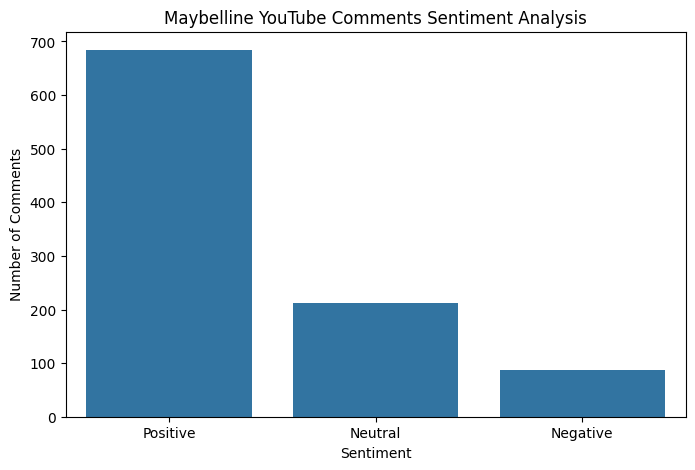

In [34]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=youtube_df,
    x="sentiment"
)

plt.title("Maybelline YouTube Comments Sentiment Analysis")

plt.xlabel("Sentiment")

plt.ylabel("Number of Comments")
plt.savefig("sentiment_bar_chart.png", dpi=300)

plt.show()

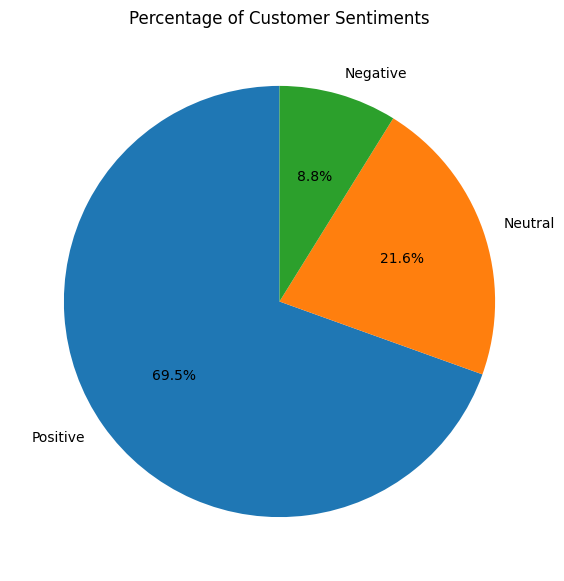

In [35]:
sentiment_counts = youtube_df["sentiment"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Customer Sentiments")
plt.savefig("sentiment_pie_chart.png", dpi=300)

plt.show()

In [30]:
from collections import Counter

positive_text = " ".join(
    positive_reviews["clean_comment"]
)

negative_text = " ".join(
    negative_reviews["clean_comment"]
)

positive_words = Counter(positive_text.split())

negative_words = Counter(negative_text.split())

print("Top Positive Words:")

print(positive_words.most_common(15))

print("\nTop Negative Words:")

print(negative_words.most_common(15))

Top Positive Words:
[('i', 1308), ('the', 775), ('and', 678), ('it', 651), ('a', 398), ('foundation', 370), ('this', 335), ('you', 324), ('my', 315), ('to', 279), ('skin', 251), ('for', 240), ('me', 236), ('is', 235), ('have', 232)]

Top Negative Words:
[('i', 177), ('it', 112), ('and', 99), ('the', 89), ('foundation', 71), ('this', 53), ('my', 46), ('a', 41), ('to', 39), ('but', 34), ('me', 34), ('t', 33), ('have', 33), ('on', 28), ('that', 28)]


In [31]:
youtube_df.to_csv(
    "final_maybelline_sentiment.csv",
    index=False
)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [32]:
total_comments = len(youtube_df)

positive_count = len(positive_reviews)

negative_count = len(negative_reviews)

neutral_count = len(neutral_reviews)

print("===== PROJECT RESULTS =====")

print("Total Comments:", total_comments)

print("Positive Comments:", positive_count)

print("Negative Comments:", negative_count)

print("Neutral Comments:", neutral_count)

===== PROJECT RESULTS =====
Total Comments: 984
Positive Comments: 684
Negative Comments: 87
Neutral Comments: 213


In [33]:
from google.colab import files

files.download("final_maybelline_sentiment.csv")

files.download("positive_reviews.csv")

files.download("negative_reviews.csv")

files.download("neutral_reviews.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>